In [1]:
from sound_simulation import *
from beamforming import *
from sensor_array import *
from scene import *
from util import *
from psd_estimation import *
from plot_utils import *
from cropac import *
from feature_extraction import *

import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Circular Array r = 10 cm')

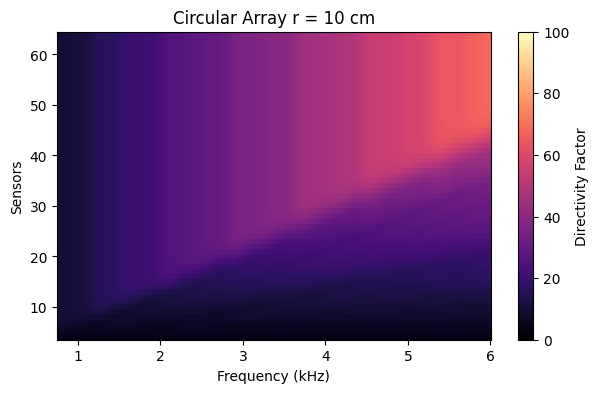

In [30]:
def array_circle(m, d = 0.1):
    
    a = np.exp(2j*np.pi*np.arange(m)/m) * d
    
    array = ArrayState()
    array.positions = np.stack((a.real, a.imag, np.zeros(m)))
    
    array.positions[0] -= np.mean(array.positions[0])
    array.positions[1] -= np.mean(array.positions[1])

    return array

c = 344
num_sensors = np.arange(4, 65)
arrays = [array_circle(m) for m in num_sensors]

fc = np.linspace(750, 6000, 512)
k = 2 * np.pi * fc / c

target_udir = polar_to_unitdir(0, np.pi/2)

df = np.zeros((len(num_sensors), len(fc)))
for i in range(len(arrays)):
    array = arrays[i]
    v = create_steering_vectors(create_distance_vectors(target_udir[None,:], array.positions), k[:,None])
    Rd = diffuse_covariance_matrices(array.positions, k)
    Rd = diagonal_load(Rd, 0.0001)
    df[i] = np.abs(np.conj(v[...,None,:]) @ np.linalg.inv(Rd) @ v[...,:,None])[:,0,0]

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)

def plot_df(ax, m, f, S_db, vmin=0, vmax=100, log_freq=False, y_label=True, x_label=True):
    # Convert frequency to kHz for display
    y = f / 1000.0
    mesh = ax.pcolormesh(y, m, S_db, shading='nearest', cmap="magma", vmin=vmin, vmax=vmax)
    if y_label:
        ax.set_xlabel("Frequency (kHz)")
    if x_label:
        ax.set_ylabel("Sensors")
    if log_freq:
        ax.set_yscale("log")
    cbar = plt.colorbar(mesh, ax=ax, format="%.0f")
    cbar.set_label("Directivity Factor")

plot_df(ax, num_sensors, fc, df)
ax.set_title("Circular Array r = 10 cm")